# Comparação dos modelos de recomendação

Avaliação offline dos cinco recomendadores (M0 a M4) no mesmo split, com os hiperparâmetros ajustados. É a base da escolha do modelo servido pela API; o texto completo está em [`docs/modelo.md`](../docs/modelo.md).

Pré-requisitos: dataset em `data/raw/steam/` (`scripts/download_data.sh`) e as dependências de `notebooks/requirements.txt`. A execução completa leva cerca de 4 minutos.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from recsys import data
from recsys.data import confidence_score, load_dataset
from recsys.evaluation import evaluate, ndcg_at_k, train_test_split
from recsys.models.content import ContentRecommender
from recsys.models.item_knn import ItemKNNRecommender
from recsys.models.popularity import PopularityRecommender
from recsys.models.svd import SVDRecommender
from recsys.train import DEFAULT_PARAMS, build_hybrid
from recsys.tuning import run_experiment, truncate_histories

RAW = ROOT / data.DEFAULT_DATA_DIR
BLUE, ORANGE, AQUA, YELLOW = "#257de0", "#f47230", "#00b894", "#f2a600"
LIGHT_BLUE, GRAY, INK, MUTED = "#84b9f3", "#c9c8c2", "#0b0b0b", "#52514e"
SURFACE = "#fcfcfb"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": "#b8b7b2",
        "axes.labelcolor": MUTED,
        "axes.titlecolor": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.axisbelow": True,
    }
)
pd.set_option("display.precision", 4)


def spread(values, gap):
    """Afasta posições de rótulos para que fiquem a pelo menos `gap` uma da outra."""
    order = np.argsort(values)
    placed = np.array(values, dtype=float)
    for prev, cur in zip(order[:-1], order[1:], strict=True):
        placed[cur] = max(placed[cur], placed[prev] + gap)
    return placed

## 1. Protocolo

- Score de confiança `1 + α·log1p(horas)` com o α escolhido no ajuste (seção 6).
- Usuários com pelo menos 5 jogos são avaliados: 20% dos jogos de cada um (semente 42) vão para o teste. Os demais usuários ficam inteiros no treino.
- Cada modelo treina no conjunto de treino, recebe o histórico de treino do usuário e recomenda 10 jogos que ele ainda não tem.
- Métricas @10 (Precision, Recall, NDCG, MAP, Hit rate), **cobertura** (fração do catálogo que aparece em alguma lista) e **novidade** (autoinformação média `-log2(popularidade)` dos jogos recomendados).

In [2]:
ALPHA = DEFAULT_PARAMS["alpha"]
ds = load_dataset(RAW, alpha=ALPHA)
split = train_test_split(ds.interactions)
n_test = pd.Series({user: len(games) for user, games in split.test.items()})

pd.Series(
    {
        "α do score de confiança": ALPHA,
        "usuários avaliados (≥ 5 jogos)": f"{len(split.test):,}",
        "interações de treino": f"{len(split.train):,}",
        "interações de teste": f"{n_test.sum():,}",
        "jogos de teste por usuário (mediana)": f"{n_test.median():.0f}",
        "catálogo": f"{len(ds.games):,} jogos",
    },
    name="valor",
).to_frame()

,valor
α do score de confiança,0.25
usuários avaliados (≥ 5 jogos),"3,757"
interações de treino,"105,867"
interações de teste,"22,934"
jogos de teste por usuário (mediana),2
catálogo,"5,153 jogos"


## 2. Modelos e resultados

| # | Modelo | Configuração |
|---|---|---|
| M0 | Popularidade | usuários distintos por jogo |
| M1 | Item-kNN | cosseno entre jogos, 20 vizinhos por jogo |
| M2 | SVD | `TruncatedSVD` com 64 fatores, fold-in do histórico |
| M3 | Conteúdo | TF-IDF de palavras e de n-gramas de caracteres dos títulos (+ tags) |
| M4 | Híbrido | M1 + M3 + M0 com pesos pelo tamanho do histórico |

In [3]:
models = {
    "M0 popularidade": PopularityRecommender(),
    "M1 item-kNN": ItemKNNRecommender(k_neighbors=DEFAULT_PARAMS["k_neighbors"]),
    "M2 SVD": SVDRecommender(n_factors=64),
    "M3 conteúdo": ContentRecommender(),
    "M4 híbrido": build_hybrid(DEFAULT_PARAMS),
}
results = {}
for name, model in models.items():
    model.fit(split.train, ds.games)
    results[name] = evaluate(model, split, n_items=len(ds.games))

METRICS = ["precision@10", "recall@10", "ndcg@10", "map@10", "hit_rate@10"]
table = pd.DataFrame.from_dict(results, orient="index")
table[[*METRICS, "coverage", "novelty", "ms_per_user"]]

,precision@10,recall@10,ndcg@10,map@10,hit_rate@10,coverage,novelty,ms_per_user
M0 popularidade,0.0626,0.1779,0.1399,0.0849,0.4248,0.0074,3.7006,0.0183
M1 item-kNN,0.1369,0.3922,0.3847,0.3088,0.6803,0.3794,6.2717,0.7995
M2 SVD,0.1168,0.3335,0.3374,0.2707,0.6149,0.1065,6.0095,2.3448
M3 conteúdo,0.0724,0.2142,0.1808,0.1248,0.4480,0.4514,8.8919,5.4973
M4 híbrido,0.1421,0.4027,0.3975,0.3186,0.6944,0.3846,6.2372,7.9522


O **híbrido (M4)** é o melhor em todas as métricas de acurácia. Entre os modelos isolados, o item-kNN (M1) vence com folga: a matriz tem 99,8% de zeros e muitos jogos com poucos usuários, o que favorece vizinhanças esparsas em relação aos 64 fatores do SVD. O conteúdo sozinho (M3) acerta pouco, mas é o que mais cobre o catálogo e o que mais recomenda jogos pouco conhecidos.

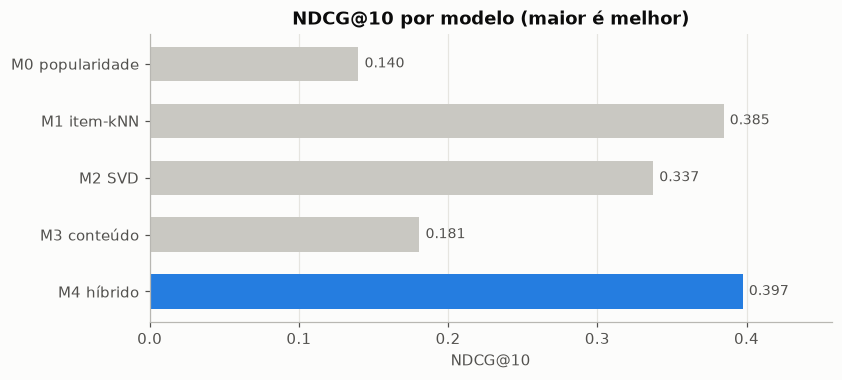

In [4]:
ndcg = table["ndcg@10"][::-1]
fig, ax = plt.subplots(figsize=(8, 3.4))
colors = [BLUE if name.startswith("M4") else GRAY for name in ndcg.index]
bars = ax.barh(ndcg.index, ndcg.to_numpy(), color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in ndcg], padding=4, color=MUTED, fontsize=9)
ax.grid(axis="y", visible=False)
ax.set(title="NDCG@10 por modelo (maior é melhor)", xlabel="NDCG@10", xlim=(0, ndcg.max() * 1.15))
plt.show()

### Acurácia × cobertura

Acurácia não é tudo: um modelo que recomenda sempre os mesmos jogos populares (38 títulos, 0,7% do catálogo) acerta alguns, mas não ajuda a descobrir nada. O híbrido mantém a cobertura do item-kNN (cerca de 38% do catálogo) com acurácia maior.

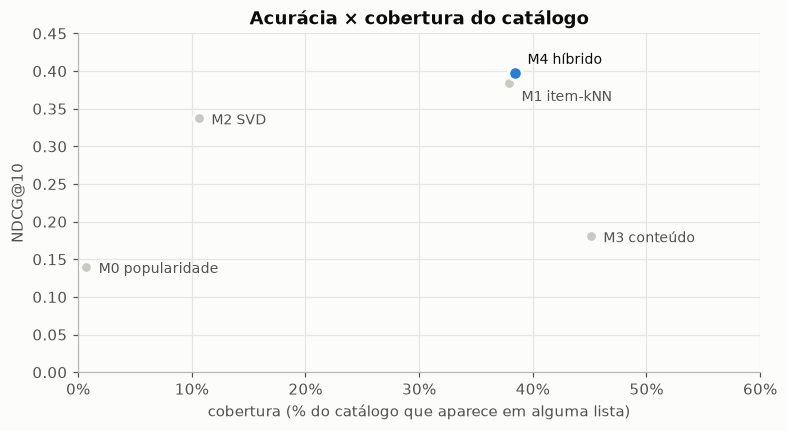

In [5]:
offsets = {"M1 item-kNN": (8, -12), "M4 híbrido": (8, 6)}
fig, ax = plt.subplots()
for name, row in table.iterrows():
    served = name.startswith("M4")
    ax.scatter(
        row["coverage"],
        row["ndcg@10"],
        s=80 if served else 60,
        color=BLUE if served else GRAY,
        edgecolor=SURFACE,
        linewidth=2,
        zorder=3,
    )
    ax.annotate(
        name,
        (row["coverage"], row["ndcg@10"]),
        xytext=offsets.get(name, (8, -4)),
        textcoords="offset points",
        color=INK if served else MUTED,
        fontsize=9,
    )
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.set(
    title="Acurácia × cobertura do catálogo",
    xlabel="cobertura (% do catálogo que aparece em alguma lista)",
    ylabel="NDCG@10",
    xlim=(0, 0.6),
    ylim=(0, 0.45),
)
plt.show()

## 3. Desempenho por tamanho do histórico

NDCG@10 de cada usuário avaliado, agrupado pela quantidade de jogos que ele tem no treino (no mínimo 4, porque o protocolo exige 5 jogos e separa ao menos 1 para o teste).

In [6]:
evaluated = split.train[split.train.user_id.isin(split.test)]
histories = {
    int(user): dict(zip(g.game_id.astype(int), g.score.astype(float), strict=True))
    for user, g in evaluated.groupby("user_id")
}
users = sorted(split.test)


def per_user_ndcg(model):
    return pd.Series(
        {
            user: ndcg_at_k(
                [
                    r.game_id
                    for r in model.recommend(histories[user], k=10, exclude=set(histories[user]))
                ],
                split.test[user],
                10,
            )
            for user in users
        }
    )


COMPARED = ["M4 híbrido", "M1 item-kNN", "M3 conteúdo", "M0 popularidade"]
BANDS = ["4–7", "8–15", "16–40", "41+"]
size = pd.Series({user: len(histories[user]) for user in users})
band = pd.cut(size, bins=[0, 7, 15, 40, np.inf], labels=BANDS)
by_size = pd.DataFrame({name: per_user_ndcg(models[name]) for name in COMPARED})
by_size = by_size.groupby(band, observed=True).mean()
by_size.insert(0, "usuários", band.value_counts().reindex(BANDS))
by_size.index.name = "jogos no treino"
by_size

,usuários,M4 híbrido,M1 item-kNN,M3 conteúdo,M0 popularidade
jogos no treino,,,,,
4–7,1568,0.4278,0.4211,0.1940,0.1236
8–15,924,0.3848,0.3737,0.1636,0.1510
16–40,744,0.3330,0.3147,0.1551,0.1378
41+,521,0.4205,0.3944,0.2083,0.1723


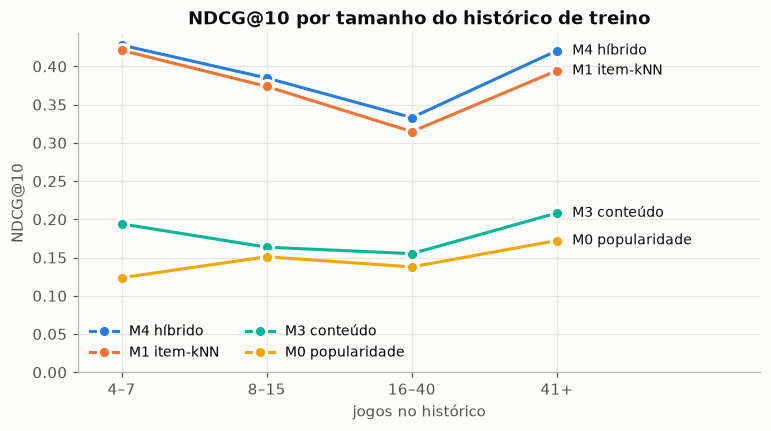

In [7]:
SERIES = {"M4 híbrido": BLUE, "M1 item-kNN": ORANGE, "M3 conteúdo": AQUA, "M0 popularidade": YELLOW}
x = np.arange(len(BANDS))
fig, ax = plt.subplots()
for name, color in SERIES.items():
    ax.plot(
        x,
        by_size[name],
        color=color,
        linewidth=2,
        marker="o",
        markersize=8,
        markeredgecolor=SURFACE,
        markeredgewidth=2,
        label=name,
    )
last = by_size[list(SERIES)].iloc[-1].to_numpy()
for name, y in zip(SERIES, spread(last, 0.022), strict=True):
    ax.annotate(
        name,
        (x[-1], y),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        color=INK,
        fontsize=9,
    )
ax.set_xticks(x, BANDS)
ax.legend(frameon=False, loc="lower left", ncols=2, fontsize=9)
ax.set(
    title="NDCG@10 por tamanho do histórico de treino",
    xlabel="jogos no histórico",
    ylabel="NDCG@10",
    xlim=(-0.3, len(BANDS) + 0.4),
    ylim=(0, None),
)
plt.show()

O híbrido fica à frente do item-kNN em todas as faixas, e a vantagem cresce com o histórico: +0,007 de NDCG com 4–7 jogos e +0,026 com 41 ou mais. O NDCG não cai de forma contínua porque quem tem muitos jogos também tem mais jogos de teste (20% do histórico), o que facilita acertar algum.

## 4. Cold start simulado

Quase metade dos usuários reais tem 1 jogo, mas eles não entram no protocolo (não sobra o que testar). Para medir esse caso, os modelos já treinados recebem só 1 ou 2 jogos sorteados do histórico de cada usuário avaliado, e o teste continua o mesmo. Amostra fixa de 1.500 usuários, a mesma do ajuste dos pesos.

In [8]:
cold = {}
for n in (1, 2):
    truncated = truncate_histories(split, n)
    label = "1 jogo" if n == 1 else f"{n} jogos"
    for name in COMPARED:
        metrics = evaluate(models[name], truncated, n_items=len(ds.games), max_users=1500)
        cold[(name, label)] = metrics["ndcg@10"]
cold = pd.Series(cold).unstack().reindex(COMPARED)
cold.columns.name = "NDCG@10 com"
cold

NDCG@10 com,1 jogo,2 jogos
M4 híbrido,0.1508,0.1879
M1 item-kNN,0.1450,0.1745
M3 conteúdo,0.0683,0.0904
M0 popularidade,0.1107,0.1121


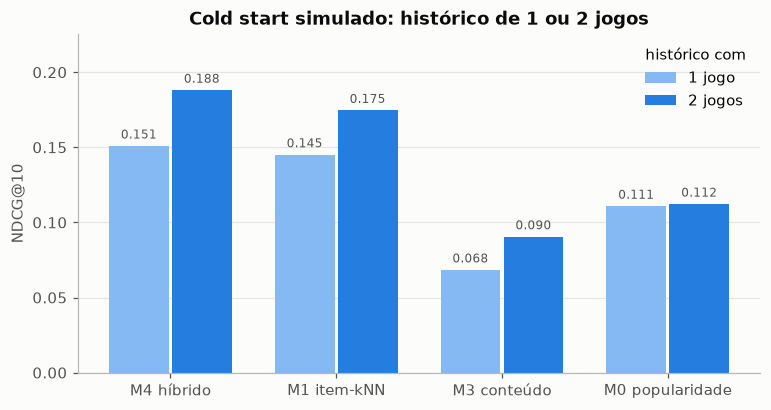

In [9]:
x = np.arange(len(COMPARED))
width = 0.36
fig, ax = plt.subplots()
for i, (col, color) in enumerate([("1 jogo", LIGHT_BLUE), ("2 jogos", BLUE)]):
    bars = ax.bar(x + (i - 0.5) * (width + 0.02), cold[col], width=width, color=color, label=col)
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in cold[col]], padding=3, fontsize=8, color=MUTED)
ax.set_xticks(x, COMPARED)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, title="histórico com", alignment="left")
ax.set(
    title="Cold start simulado: histórico de 1 ou 2 jogos",
    ylabel="NDCG@10",
    ylim=(0, cold.to_numpy().max() * 1.2),
)
plt.show()

Com 1 ou 2 jogos, o híbrido usa os pesos 0,3 / 0,3 / 0,4 (CF / conteúdo / popularidade) e fica acima de todos os modelos isolados (0,188 contra 0,175 do item-kNN com 2 jogos). O conteúdo sozinho é o pior aqui: com 1 ou 2 títulos, a semelhança de nomes diz pouco. Para um usuário sem nenhum jogo, o híbrido recomenda só por popularidade (M0).

## 5. Ajuste do α do score de confiança

O híbrido é treinado e avaliado para cada α (amostra fixa de 1.500 usuários, como em `python -m recsys.tuning`). Com α = 0, o score ignora as horas: só conta a compra.

In [10]:
ALPHAS = [0, 0.25, 0.5, 1, 2]
alpha_rows = {
    alpha: run_experiment(
        ds.interactions, ds.games, {**DEFAULT_PARAMS, "alpha": alpha}, max_users=1500
    )
    for alpha in ALPHAS
}
alpha_table = pd.DataFrame.from_dict(alpha_rows, orient="index")[[*METRICS, "coverage"]]
alpha_table.index.name = "α"
alpha_table

,precision@10,recall@10,ndcg@10,map@10,hit_rate@10,coverage
α,,,,,,
0.00,0.1341,0.3776,0.3810,0.3077,0.6553,0.2628
0.25,0.1355,0.3875,0.3825,0.3061,0.6713,0.2453
0.50,0.1336,0.3819,0.3743,0.2969,0.6707,0.2628
1.00,0.1246,0.3627,0.3467,0.2709,0.6480,0.2932
2.00,0.1109,0.3355,0.3094,0.2359,0.6160,0.3297


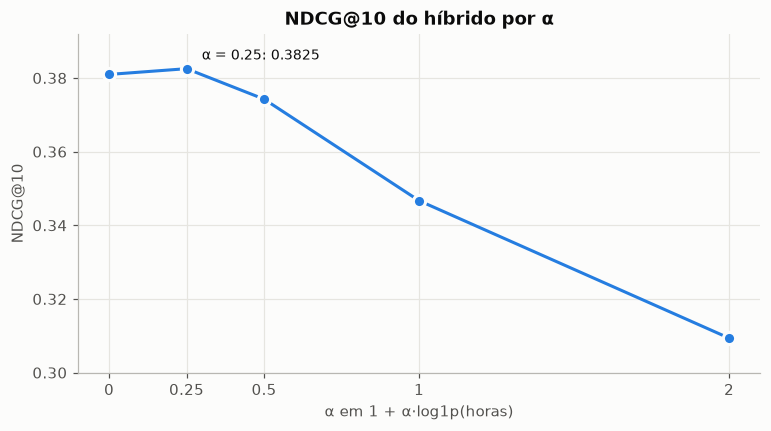

In [11]:
best = alpha_table["ndcg@10"].idxmax()
fig, ax = plt.subplots()
ax.plot(
    alpha_table.index,
    alpha_table["ndcg@10"],
    color=BLUE,
    linewidth=2,
    marker="o",
    markersize=8,
    markeredgecolor=SURFACE,
    markeredgewidth=2,
)
ax.annotate(
    f"α = {best:g}: {alpha_table.loc[best, 'ndcg@10']:.4f}",
    (best, alpha_table.loc[best, "ndcg@10"]),
    xytext=(10, 6),
    textcoords="offset points",
    color=INK,
    fontsize=9,
)
ax.set_xticks(ALPHAS, [f"{a:g}" for a in ALPHAS])
ax.set(
    title="NDCG@10 do híbrido por α",
    xlabel="α em 1 + α·log1p(horas)",
    ylabel="NDCG@10",
    ylim=(0.30, 0.392),
)
plt.show()

As horas jogadas ajudam pouco: α = 0 quase empata com o melhor valor. Valores altos deixam poucos jogos muito jogados dominarem o histórico e pioram a acurácia. O modelo servido usa **α = 0,25**. O ajuste do número de vizinhos e dos pesos de cada faixa de histórico está em `docs/modelo.md`.

## 6. Exemplo: recomendações explicadas

O híbrido final treina com todos os dados (como em `python -m recsys.train`). Um jogador de *Fallout 4*, *The Witcher 3* e *Civilization V*:

In [12]:
final = build_hybrid(DEFAULT_PARAMS)
final.fit(ds.interactions, ds.games)
names = ds.games.set_index("game_id")["name"].to_dict()


def show(recs):
    return pd.DataFrame(
        [{"jogo": names[r.game_id], "score": round(r.score, 3), "motivo": r.reason} for r in recs]
    )


hours = {2: 80, 512: 120, 43: 30}  # Fallout 4, The Witcher 3, Civilization V
history = {game: float(confidence_score(h, ALPHA)) for game, h in hours.items()}
show(final.recommend(history, k=8, exclude=set(history)))

,jogo,score,motivo
0,Fallout New Vegas,0.784,Porque você jogou Fallout 4
1,The Witcher 2 Assassins of Kings Enhanced Edition,0.757,Porque você jogou The Witcher 3 Wild Hunt
2,The Elder Scrolls V Skyrim,0.667,Porque você jogou Fallout 4
3,The Witcher 3 Wild Hunt - New Finisher Animations,0.582,Porque você jogou The Witcher 3 Wild Hunt
4,Dishonored,0.536,Porque você jogou Fallout 4
5,Sid Meier's Civilization V Brave New World,0.477,Porque você jogou Sid Meier's Civilization V
6,The Witcher 3 Wild Hunt - Expansion Pass,0.444,Porque você jogou The Witcher 3 Wild Hunt
7,Fallout New Vegas Dead Money,0.443,Porque você jogou Fallout 4


Um usuário novo, sem nenhum jogo, recebe os mais populares:

In [13]:
show(final.recommend({}, k=5))

,jogo,score,motivo
0,Dota 2,1.000,Popular entre jogadores
1,Team Fortress 2,0.456,Popular entre jogadores
2,Unturned,0.292,Popular entre jogadores
3,Counter-Strike Global Offensive,0.259,Popular entre jogadores
4,Half-Life 2 Lost Coast,0.166,Popular entre jogadores


Um jogo cadastrado depois do treino entra no modelo de conteúdo na hora (`add_game`), sem retreino. Na API, isso acontece no `POST /games`:

In [14]:
final.add_game(99_999, "Fallout 5", ["rpg", "pós-apocalíptico"])
names[99_999] = "Fallout 5"
show(final.content.similar_games(2, k=5))

,jogo,score,motivo
0,Fallout,0.988,Parecido com Fallout 4
1,Fallout 2,0.983,Parecido com Fallout 4
2,Fallout 3,0.980,Parecido com Fallout 4
3,Fallout 5,0.796,Parecido com Fallout 4
4,Fallout Tactics,0.623,Parecido com Fallout 4


## 7. Conclusões

1. **Modelo servido: M4 híbrido**, o melhor em todas as métricas de acurácia (NDCG@10 0,3975 contra 0,3847 do melhor modelo isolado), com cobertura equivalente à do item-kNN.
2. O **item-kNN** é o componente colaborativo: melhor que o SVD neste dataset e atualizável online, porque pontua direto do histórico.
3. Os **pesos dependem do tamanho do histórico**: com 1–2 jogos, popularidade (0,4) e conteúdo (0,3) ganham espaço; com 3 ou mais, o CF domina (0,7). Assim o híbrido fica à frente em todas as faixas, inclusive no cold start simulado.
4. As **horas jogadas** ajudam pouco; α = 0,25 é o melhor valor testado.